# Single-line clean catalogs

A proposal made without a secondary limit is for **single-line clean catalogs**. The catalog holds the galaxies with Hα
above the primary flux limit, each with its true redshift, and no interlopers. The secondary limit only decides which
of them count as single-line galaxies.

1. **`base.make_proposal((1.0, 1.2), line="Ha", flux_limit=1.5e-16)`**, without a secondary limit, makes the proposal.
   Its summary gives, against redshift, the share of the Hα galaxies that are *true* single-line galaxies: those with
   no other line above 0.3, 0.4 or 0.5 times the primary limit (`secondary_ratios`).
2. **`proposal.make_catalog(out_dir=...)`** makes the catalog with one line per galaxy. Every galaxy is a single-line
   galaxy (`id_outcome` 2), and its line is Hα even where its [O III] is brighter.
3. **`proposal.make_catalog(secondary_flux_limit=..., out_dir=...)`** makes a catalog of the same galaxies with their
   other lines above that limit. Only those without another line are single-line galaxies (`id_outcome` 2); the others
   are multi-line (1).

Neither step takes a confusion table or interloper fractions. For a catalog with interlopers, give the proposal a
secondary limit (notebooks 01, 02 and 04).

Run it on a CPU node, from the package directory:
`sbatch scripts/run_notebook.sh notebooks/05_single_line_clean_catalogs.ipynb` (about 2 minutes). The catalogs go to
`$PSCRATCH/RomanMocks/examples/`.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, plotting
from romanmock.plotting import TEXT_PRIMARY, TEXT_SECONDARY, feature_color

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)

<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>


## Step 1: the proposal

The summary gives the Hα galaxies against redshift and the share of them with no other line above 4.5, 6 and
7.5 × 10⁻¹⁷. `proposal.plot()` draws that share.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] no secondary limit: a single-line clean catalog, no interlopers; the summary gives the true single-line share at 0.3, 0.4, 0.5 times the primary limit


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 38 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16; one line per galaxy: no secondary limit
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 57 % of the detected
                galaxies with both lines in the bandpass
  sample        12,617,496 galaxies with Hα detected at 1.0 ≤ z < 1.2 (4,894 per deg²)
  interlopers   none: a single-line clean catalog, every redshift the true one

── Hα single-line galaxies against redshift ────────────────────────────────────────────────────────
  without a secondary limit (this proposal) every one of the Hα galaxies is a single-line galaxy.
  With one, only those without another line above it are: their share in %, for secondary limits of
  0.3, 0.4, 0.5 times the primary one
  z          Hα galaxies¹  4.5e-1

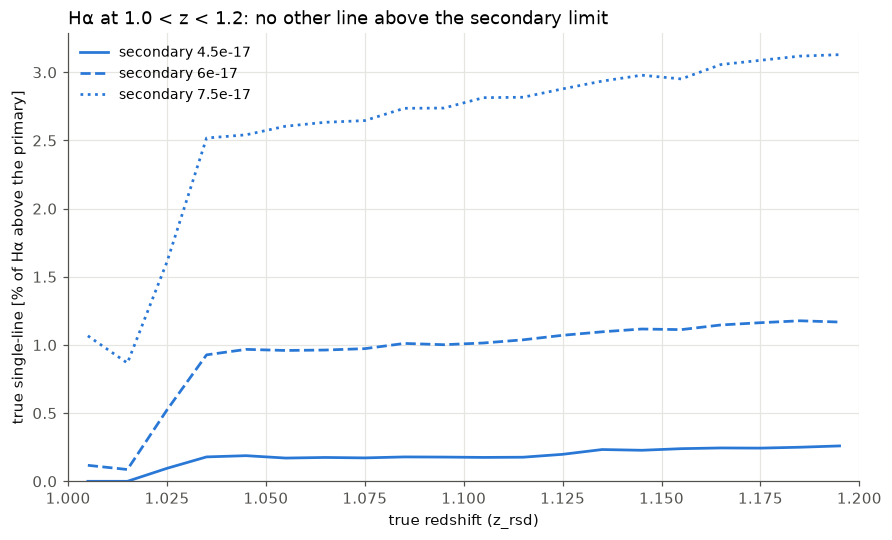

In [2]:
proposal = base.make_proposal((1.0, 1.2), line="Ha", flux_limit=1.5e-16, n_workers=N_WORKERS)
proposal.plot()
plt.show()

Without a secondary limit the sample is the 12,617,496 galaxies with Hα above the primary limit (4,894 per deg²).

* **True single-line Hα galaxies:** 0.17 % at a secondary limit of 4.5 × 10⁻¹⁷, 0.92 % at 6 × 10⁻¹⁷ and 2.55 % at
  7.5 × 10⁻¹⁷.
* **Each share rises with z**: at 7.5 × 10⁻¹⁷, from 2.5 % at z = 1.03 to 3.1 % at z = 1.2.
* **All are lower below z ≈ 1.025**, where [S III] λ9532 is still in the bandpass and is often detected as a second
  line.

## Step 2: one line per galaxy

Without a secondary limit, every galaxy of the catalog has one detected line, Hα.

In [3]:
cat_one = proposal.make_catalog(out_dir=OUT / "Ha_z1p0_1p2_single_clean", n_workers=N_WORKERS)

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 37 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16; one line per galaxy: no secondary limit
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   every single line identified correctly
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     100,805,121 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                           number     share
  ─────────────────────────────  ──────────  ────────
  single line, correct redshift  12,617,496  100.00 %
  all                            12,617,496  100.00 %

── Lines in the bandpass, 10000–19300 Å, for 1.0 ≤ z_assigned ≤ 1.2 ────────────────────────────────
  line         redshift     λ_obs [Å]      detected  identified   brightest  mista


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_single_clean/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


## Step 2 with a secondary limit

This is the same proposal with a secondary limit of half the primary one, 7.5 × 10⁻¹⁷. The catalog holds the same
galaxies, now with their other lines above that limit.

In [4]:
cat_two = proposal.make_catalog(secondary_flux_limit=7.5e-17, out_dir=OUT / "Ha_z1p0_1p2_single_clean_7p5e-17",
                                n_workers=N_WORKERS)

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 33 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 7.50e-17); only galaxies with Hα above the primary
                   limit
  line fluxes      rescaled (galacticus_like); [O III] doublet per_galaxy
  identification   every single line identified correctly
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     72,783,739 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                           number     share
  ─────────────────────────────  ──────────  ────────
  multi-line                     12,295,609   97.45 %
  single line, correct redshift     321,887    2.55 %
  all                            12,617,496  100.00 %

── Lines in the bandpass, 10000–19300 Å, for 1.0 ≤ z_assigned ≤ 1.2 ────────────


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_single_clean_7p5e-17/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


## Checks

Both catalogs should hold the same galaxies, the proposal's sample, with no interlopers and every redshift the true one.
In the catalog with a secondary limit, the single-line share against redshift should be the proposal's at 0.5 times the
primary limit.

 one line per galaxy: 12,617,496 galaxies, 100.00 % single-line, 0 interlopers, largest |z_assigned - z_rsd| 0.0e+00
   secondary 7.5e-17: 12,617,496 galaxies, 2.55 % single-line, 0 interlopers, largest |z_assigned - z_rsd| 0.0e+00
        the proposal: 12,617,496 galaxies with Hα above the primary limit


the same galaxies in both: True
single-line at 7.5e-17: 321,887 in the catalog, 321,887 counted by the proposal; largest difference per bin 0.0e+00


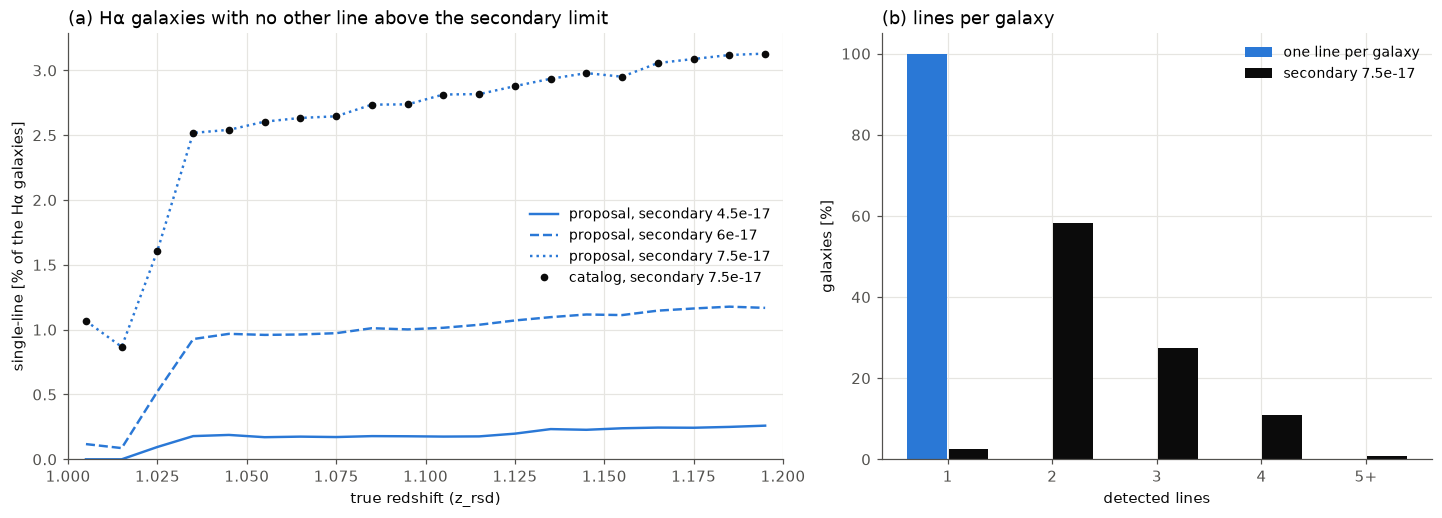

In [5]:
for name, c in (("one line per galaxy", cat_one), ("secondary 7.5e-17", cat_two)):
    single = c["id_outcome"] == 2
    print(f"{name:>20s}: {len(c):,} galaxies, {100 * single.mean():.2f} % single-line, "
          f"{int((c['id_outcome'] == 3).sum())} interlopers, "
          f"largest |z_assigned - z_rsd| {np.max(np.abs(c['redshift_assigned'] - c['redshift_rsd'])):.1e}")
print(f"{'the proposal':>20s}: {proposal.n_sample:,} galaxies with Hα above the primary limit")
print("the same galaxies in both:", np.array_equal(np.sort(cat_one["gal_id"]), np.sort(cat_two["gal_id"])))

# the single-line share against true redshift, in the bins of the proposal
inside = proposal.inside
edges = np.append(proposal.z_edges[:-1][inside], proposal.z_edges[1:][inside][-1])
single = cat_two["id_outcome"] == 2
n_all = np.histogram(cat_two["redshift_rsd"], edges)[0]
n_single = np.histogram(cat_two["redshift_rsd"][single], edges)[0]
z, expected = proposal.single_line_fraction(0.5)
j = proposal.settings["secondary_ratios"].index(0.5)
print(f"single-line at 7.5e-17: {single.sum():,} in the catalog, "
      f"{int(proposal.counts['nq_single'][j][inside, proposal.line_names.index('Ha')].sum()):,} counted by the proposal; "
      f"largest difference per bin {np.max(np.abs(n_single / n_all - expected)):.1e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True, gridspec_kw={"width_ratios": [1.3, 1]})
for r, ls in zip(proposal.settings["secondary_ratios"], ("-", "--", ":")):
    zr, f = proposal.single_line_fraction(r)
    ax1.plot(zr, 100 * f, color=feature_color("Ha"), ls=ls, lw=1.6, label=f"proposal, secondary {r * 1.5e-16:.2g}")
ax1.plot(z, 100 * n_single / n_all, "o", color=TEXT_PRIMARY, ms=4, label="catalog, secondary 7.5e-17")
ax1.set_xlim(1.0, 1.2)
ax1.set_ylim(bottom=0)
ax1.set_xlabel("true redshift (z_rsd)")
ax1.set_ylabel("single-line [% of the Hα galaxies]")
ax1.set_title("(a) Hα galaxies with no other line above the secondary limit", loc="left")
ax1.legend(fontsize=9)
k = np.arange(1, 6)
for c, label, color, dx in ((cat_one, "one line per galaxy", feature_color("Ha"), -0.2),
                            (cat_two, "secondary 7.5e-17", TEXT_PRIMARY, 0.2)):
    n_det = np.bincount(np.minimum(c["n_det"], 5), minlength=6)[1:6]
    ax2.bar(k + dx, 100 * n_det / len(c), width=0.38, color=color, label=label)
ax2.set_xticks(k, ["1", "2", "3", "4", "5+"])
ax2.set_xlabel("detected lines")
ax2.set_ylabel("galaxies [%]")
ax2.set_title("(b) lines per galaxy", loc="left")
ax2.legend(fontsize=9)
plt.show()

* **The same galaxies, no interlopers.** Both catalogs hold the 12,617,496 galaxies of the proposal, and every
  redshift is the true one.
* **One line per galaxy:** every galaxy has one detected line, Hα, and is a single-line galaxy.
* **With a secondary limit of 7.5 × 10⁻¹⁷:** 321,887 galaxies (2.55 %) are single-line, exactly the proposal's
  count, in every redshift bin. The others are multi-line: 58.3 % of the galaxies have two lines, 27.4 % three and
  11.8 % four or more.
* **[O III] is brighter than Hα in 42.5 % of the galaxies** (5,365,759, the "brightest" column of the line report).
  With one line per galaxy their line is still Hα, so the catalog holds every Hα galaxy above the primary limit.

## S/N thresholds

This is a single-line proposal with S/N ≥ 5 for the primary line and the size of each galaxy. The table gives the true
single-line shares at secondary S/N of 1.5, 2 and 2.5.

In [6]:
proposal_snr = base.make_proposal((1.0, 1.2), line="Ha", snr=5, size="r50_disk_2d", n_workers=N_WORKERS)

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] no secondary limit: a single-line clean catalog, no interlopers; the summary gives the true single-line share at 0.3, 0.4, 0.5 times the primary limit


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 42 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5, size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x min zodi; one line
                per galaxy: no secondary limit
  line fluxes   rescaled (galacticus_like)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 31 % of the detected
                galaxies with both lines in the bandpass
  sample        16,449,077 galaxies with Hα detected at 1.0 ≤ z < 1.2 (6,380 per deg²)
  interlopers   none: a single-line clean catalog, every redshift the true one

── Hα single-line galaxies against redshift ────────────────────────────────────────────────────────
  without a secondary limit (this proposal) every one of the Hα galaxies is a single-line galaxy.
  With one, only those without another line above it are: their share in %, for secondary limits

With S/N ≥ 5 and no secondary S/N, the sample is 16,449,077 galaxies (6,380 per deg²). The true single-line share is
3.65 % at secondary S/N 1.5, 10.1 % at 2 and 18.8 % at 2.5, far above the flux route, because [O III] falls at the
noisy blue edge of the grism. `make_catalog(secondary_snr=..., out_dir=...)` makes its clean catalogs in the same
way.

## Summary

* **`make_proposal` without a secondary limit** (and without `interloper_fraction`) proposes single-line clean
  catalogs. Its sample is every galaxy with Hα above the primary limit (12.62 M at 1.0–1.2). The summary gives the
  true single-line share at 0.3, 0.4 and 0.5 times the primary limit: 0.17, 0.92 and 2.55 %.
* **`make_catalog(out_dir=...)`** makes the catalog with one line per galaxy, every galaxy single-line.
  **`make_catalog(secondary_flux_limit=..., out_dir=...)`** makes the same galaxies with their other lines above
  that limit. At 7.5 × 10⁻¹⁷, 2.55 % of them are single-line, as the proposal said.
* Neither has interlopers, and neither takes a confusion table or interloper fractions. For interlopers, give the
  proposal `interloper_fraction` (notebook 04) or a secondary limit (notebooks 01 and 02).
* The notebook ran in 2.7 minutes on a CPU node.